<a href="https://colab.research.google.com/github/juliet-karpah/wind-power-forecasting/blob/main/wind_power_data_exploration_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Data Card
Source: https://zenodo.org/records/22662930

DOI: 10.5281/zenodo.14870021

hub height: 59 m

Rotor: 82 m

Rated power: 2.3 MW

Number of turbines/sites: 21 Siemens SWT-2.3-VS-82 turbines

License: Creative Commons Attribution 4.0 (CC-BY-4.0)

Date: 2025

File structure: year zipped file -> monthly CSV files ->[table]_ [year]_[month].csv
Join data by station_id, which is StationId = turbine number + 2304509, and timestamp, which is the end of the 10-minute interval in UTC


## Column Definition

| Field | Unit | Meaning | Table |
| :--- | :---: | :---: | ---: |
| wtc_ActPower | kW | active power produced | tblSCTurGrid |
| wtc_AcWindSp | m/s | wind speed | tblSCTurbine |
| wtc_AmbieTmp | C | ambient temperature | tblSCTurTemp	|
| wtc_ActualWindDirection | deg | wind direction | tblSCTurbine |
| Timestamp | UTC | end of 10 minute period | all |
| stationid | none | turbine ID: turbine number + 2304509, so T01 = 2304510 | all |
| wtc_PowerRef_endvalue | kW | power setpoint at the end of the period| tblSCTurbine |
| wtc_WTOperSt | none | turbine operating state | tblSCTurbine |
| wtc_ScInOper_timeon | s | seconds the turbine was running in the period | tblSCTurFlag |
| wtc_ScReToOp_timeon | s | seconds ready to operate in period | tblSCTurFlag |
| wtc_ScTurSto_timeon | s | seconds a turbine error was active in the period | tblSCTurFlag |
|ActivePowerMean| MW | Active power | tblGridScientific	 |
| ReActivePowerMean | MVar | Reactive power | tblGridScientific |
|ActiveEnergy, ReActiveEnergy | MWh | Active / reactive energy | tblGridScientific |
| VoltageMean, CurrentMean | kV, A | Voltage, current | tblGridScientific |
| Frequency, PowerFactor | Hz, none | Frequency, power factor | tblGrid |
| ActivePowerExport, ActivePowerImport | kWh, kVarh | Exported / imported energy | tblGrid |

## Task

| Task | Target | Horizon | Input available |Evaluation |
|:--- | :---: | :---: | :---: | ---: |
| Expected power model |wtc_ActPower|None | wtc_AcWindSp, wtc_AmbieTmp, <br><br>wtc_ActualWindDirection | tbd |
| Short-term power forecast | wtc_ActPower sum 21 turbines | 10,20,30mins, 1h,3h,6h | wtc_AcWindSp, wtc_AmbieTmp | tbd |
| Anomaly detection | No target,output is a comparison <br><br>between how a turbine performs and <br><br>the average power by<br><br> 20 turbines at a timestamp | None | expected power results from task 1,<br><br>cross turbine comparison at <br><br> each timestamp | tbd |
| 24-hour wind power forecast | farm level power reading for each hour of the next day | 24hr | external weather data from ERA5 + data at issue time| tbd |


In [42]:
import zipfile
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [19]:
!wget -O filename "https://zenodo.org/records/22662930/files/2025.zip?download=1"

--2026-11-21 18:32:45--  https://zenodo.org/records/22662930/files/2025.zip?download=1
Resolving zenodo.org (zenodo.org)... 188.185.40.132, 188.185.45.63, 188.185.51.60, ...
Connecting to zenodo.org (zenodo.org)|188.185.40.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1596220683 (1.5G) [application/octet-stream]
Saving to: ‘filename’

filename            100%[===================>]   1.49G  8.64MB/s    in 3m 56s  

2026-11-21 18:36:41 (6.45 MB/s) - ‘filename’ saved [1596220683/1596220683]



In [20]:
zf = zipfile.ZipFile("/content/filename")

In [21]:
zf.namelist()

['tblAlarmLog_2025_01.csv',
 'tblAlarmLog_2025_02.csv',
 'tblAlarmLog_2025_03.csv',
 'tblAlarmLog_2025_04.csv',
 'tblAlarmLog_2025_05.csv',
 'tblAlarmLog_2025_06.csv',
 'tblAlarmLog_2025_07.csv',
 'tblAlarmLog_2025_08.csv',
 'tblAlarmLog_2025_09.csv',
 'tblAlarmLog_2025_10.csv',
 'tblAlarmLog_2025_11.csv',
 'tblAlarmLog_2025_12.csv',
 'tblDailySummary_2025_01.csv',
 'tblDailySummary_2025_02.csv',
 'tblDailySummary_2025_03.csv',
 'tblDailySummary_2025_04.csv',
 'tblDailySummary_2025_05.csv',
 'tblDailySummary_2025_06.csv',
 'tblDailySummary_2025_07.csv',
 'tblDailySummary_2025_08.csv',
 'tblDailySummary_2025_09.csv',
 'tblDailySummary_2025_10.csv',
 'tblDailySummary_2025_11.csv',
 'tblDailySummary_2025_12.csv',
 'tblGridScientific_2025_01.csv',
 'tblGridScientific_2025_02.csv',
 'tblGridScientific_2025_03.csv',
 'tblGridScientific_2025_04.csv',
 'tblGridScientific_2025_05.csv',
 'tblGridScientific_2025_06.csv',
 'tblGridScientific_2025_07.csv',
 'tblGridScientific_2025_08.csv',
 'tblGri

In [22]:
with zf.open('tblSCTurbine_2025_01.csv') as f:
  df_turbine_01 = pd.read_csv(f)


In [23]:
df_turbine_01.shape

(93765, 96)

In [24]:
df_turbine_01.columns

Index(['TimeStamp', 'StationId', 'wtc_CurTime_endvalue', 'wtc_SecAnemo_min',
       'wtc_SecAnemo_max', 'wtc_SecAnemo_mean', 'wtc_SecAnemo_stddev',
       'wtc_YawPos_min', 'wtc_YawPos_max', 'wtc_YawPos_mean',
       'wtc_YawPos_stddev', 'wtc_GenRpm_min', 'wtc_GenRpm_max',
       'wtc_GenRpm_mean', 'wtc_GenRpm_stddev', 'wtc_MainSRpm_min',
       'wtc_MainSRpm_max', 'wtc_MainSRpm_mean', 'wtc_MainSRpm_stddev',
       'wtc_PitchRef_BladeA_min', 'wtc_PitchRef_BladeA_max',
       'wtc_PitchRef_BladeA_mean', 'wtc_PitchRef_BladeA_stddev',
       'wtc_PitchRef_BladeB_min', 'wtc_PitchRef_BladeB_max',
       'wtc_PitchRef_BladeB_mean', 'wtc_PitchRef_BladeB_stddev',
       'wtc_PitchRef_BladeC_min', 'wtc_PitchRef_BladeC_max',
       'wtc_PitchRef_BladeC_mean', 'wtc_PitchRef_BladeC_stddev',
       'wtc_PitcRefA_min', 'wtc_PitcRefA_max', 'wtc_PitcRefA_mean',
       'wtc_PitcRefA_stddev', 'wtc_PriAnemo_min', 'wtc_PriAnemo_max',
       'wtc_PriAnemo_mean', 'wtc_PriAnemo_stddev', 'wtc_TwrHumid_mean',


In [25]:
df_turbine_01.head()

,TimeStamp,StationId,wtc_CurTime_endvalue,wtc_SecAnemo_min,wtc_SecAnemo_max,wtc_SecAnemo_mean,wtc_SecAnemo_stddev,wtc_YawPos_min,wtc_YawPos_max,wtc_YawPos_mean,...,wtc_BoostAct_max,wtc_BoostAct_mean,wtc_BoostAct_stddev,wtc_ActualWindDirection_min,wtc_ActualWindDirection_max,wtc_ActualWindDirection_mean,wtc_ActualWindDirection_stddev,wtc_WTOperSt_min,wtc_WTOperSt_max,wtc_WTOperSt_endvalue
0,2025-01-01 00:00:00,2304510,2024-12-31 23:59:58,9.80,20.570000,14.62702,1.689839,268.799988,275.500000,272.159912,...,0.0,0.0,0.0,251.000000,303.200012,273.865387,10.473000,0,0,0
1,2025-01-01 00:00:00,2304511,2024-12-31 23:59:58,8.95,19.150000,13.05362,1.642682,237.300003,245.100006,239.708405,...,0.0,0.0,0.0,210.500000,271.000000,241.686798,11.395720,0,0,0
2,2025-01-01 00:00:00,2304512,2024-12-31 23:59:58,9.62,20.830000,14.46624,1.924990,248.699997,254.600006,252.036606,...,0.0,0.0,0.0,224.800003,285.899994,253.524704,9.083889,0,0,0
3,2025-01-01 00:00:00,2304513,2024-12-31 23:59:59,8.48,22.530001,14.94520,1.681559,251.600006,259.799988,255.515396,...,0.0,0.0,0.0,235.199997,293.399994,257.030609,8.340936,0,0,0
4,2025-01-01 00:00:00,2304514,2024-12-31 23:59:58,8.87,20.629999,14.05153,1.751299,224.899994,235.300003,230.949005,...,0.0,0.0,0.0,203.600006,265.399994,232.339798,11.225720,0,0,0


In [26]:
df_turbine_01.describe()

,StationId,wtc_SecAnemo_min,wtc_SecAnemo_max,wtc_SecAnemo_mean,wtc_SecAnemo_stddev,wtc_YawPos_min,wtc_YawPos_max,wtc_YawPos_mean,wtc_YawPos_stddev,wtc_GenRpm_min,...,wtc_BoostAct_max,wtc_BoostAct_mean,wtc_BoostAct_stddev,wtc_ActualWindDirection_min,wtc_ActualWindDirection_max,wtc_ActualWindDirection_mean,wtc_ActualWindDirection_stddev,wtc_WTOperSt_min,wtc_WTOperSt_max,wtc_WTOperSt_endvalue
count,9.376500e+04,93765.000000,93765.000000,93765.000000,93765.000000,93765.000000,93765.000000,93765.000000,93765.000000,93765.000000,...,93765.0,93765.0,93765.0,93765.000000,93765.000000,93765.000000,93765.000000,93765.000000,93765.000000,93765.000000
mean,2.304520e+06,5.363061,11.390206,8.231453,1.055050,232.910721,242.952194,238.129698,2.322434,898.073439,...,0.0,0.0,0.0,175.167636,282.389444,236.329861,12.082919,0.587373,0.818632,0.677801
std,6.055333e+00,3.007387,6.069450,4.324205,0.625339,67.288542,63.918152,65.330005,2.984870,386.816648,...,0.0,0.0,0.0,87.252564,58.189239,67.119406,7.953750,1.302124,1.480558,1.372378
min,2.304510e+06,0.010000,0.010000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,0.600000,...,0.0,0.0,0.0,0.100000,36.400002,0.008113,1.962926,0.000000,0.000000,0.000000
25%,2.304515e+06,3.090000,6.930000,5.117976,0.564325,208.500000,220.100006,214.821793,1.077548,630.700012,...,0.0,0.0,0.0,129.399994,254.800003,210.882095,8.030419,0.000000,0.000000,0.000000
50%,2.304520e+06,5.150000,10.870000,7.910434,0.989484,241.899994,248.699997,245.168503,1.682117,792.400024,...,0.0,0.0,0.0,202.399994,284.799988,244.375305,10.096010,0.000000,0.000000,0.000000
75%,2.304525e+06,7.180000,15.470000,11.015960,1.417225,274.000000,282.299988,278.178497,2.827068,1230.099976,...,0.0,0.0,0.0,236.699997,327.000000,278.549408,13.531870,0.000000,3.000000,0.000000
max,2.304530e+06,20.350000,46.830002,29.739571,6.954441,359.799988,360.000000,359.990204,100.821098,1533.000000,...,0.0,0.0,0.0,322.700012,360.000000,359.995514,103.902000,9.000000,9.000000,9.000000


In [27]:
df_turbine_01.groupby("TimeStamp").size()

,0
TimeStamp,
2025-01-01 00:00:00,21
2025-01-01 00:10:00,21
2025-01-01 00:20:00,21
2025-01-01 00:30:00,21
2025-01-01 00:40:00,21
...,...
2025-01-31 23:20:00,21
2025-01-31 23:30:00,21
2025-01-31 23:40:00,21


In [28]:
df_turbine_01["wtc_AcWindSp_mean"].isna().sum()

np.int64(0)

In [30]:
df_turbine_01["wtc_AcWindSp_mean"].describe()

,wtc_AcWindSp_mean
count,93765.000000
mean,7.242828
std,4.068485
min,0.088868
25%,4.209792
50%,6.684039
75%,9.700160
max,28.744160


In [31]:
with zf.open('tblSCTurGrid_2025_01.csv') as f:
  df_tblSCTurGrid_01 = pd.read_csv(f)

In [34]:
df_tblSCTurGrid_01["wtc_ActPower_mean"].describe()

,wtc_ActPower_mean
count,93765.000000
mean,725.867142
std,767.216431
min,-20.331720
25%,70.728020
50%,412.299988
75%,1292.113037
max,2302.763916


In [41]:
(df_tblSCTurGrid_01["wtc_ActPower_mean"] < 0).sum()

np.int64(18188)

In [50]:
df_tblSCTurGrid_01["wtc_ActPower_mean"].value_counts().head(10)

,count
wtc_ActPower_mean,
2299.020020,5
2294.832031,4
2299.031982,4
2296.795898,4
2297.040039,4
2299.132080,4
2299.702881,4
2296.080078,3
2291.374023,3


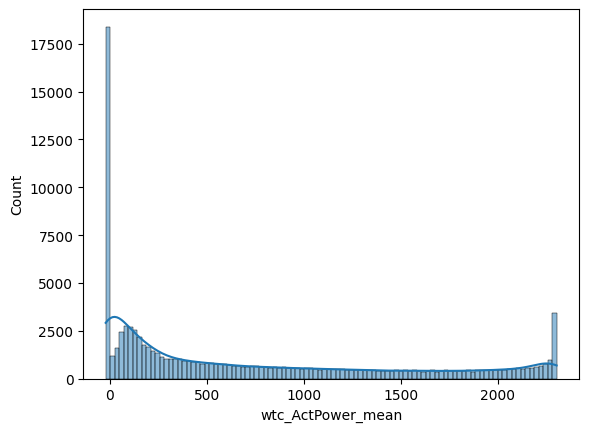

In [49]:
sns.histplot(data=df_tblSCTurGrid_01, x='wtc_ActPower_mean', bins=100, kde=True) # set kde=False to hide the curve
plt.show()

In [47]:
(df_tblSCTurGrid_01["wtc_ActPower_mean"] < 100).mean()

np.float64(0.28706873566895963)

In [44]:
group_by_TimeStamp = df_tblSCTurGrid_01.groupby("TimeStamp")["wtc_ActPower_mean"]

In [45]:
group_by_TimeStamp.sum()

,wtc_ActPower_mean
TimeStamp,
2025-01-01 00:00:00,43181.386108
2025-01-01 00:10:00,39075.123108
2025-01-01 00:20:00,39120.233032
2025-01-01 00:30:00,35489.721436
2025-01-01 00:40:00,31591.189819
...,...
2025-01-31 23:20:00,9748.775055
2025-01-31 23:30:00,9049.561218
2025-01-31 23:40:00,8283.302780


In [35]:
with zf.open('tblSCTurTemp_2025_01.csv') as f:
  df_tblSCTurTemp_01 = pd.read_csv(f)

In [37]:
df_tblSCTurTemp_01['wtc_AmbieTmp_mean'].describe()

,wtc_AmbieTmp_mean
count,93765.000000
mean,2.898464
std,3.682217
min,-4.000000
25%,0.000000
50%,2.000000
75%,5.000000
max,13.702380


In [51]:
merged_df = pd.merge(df_turbine_01, df_tblSCTurGrid_01, how='inner', on=['TimeStamp', 'StationId'])

In [60]:
merged_df["curtailed"] = merged_df["wtc_PowerRef_endvalue"] < 2300

## T01 analysis


In [61]:
t01_merged_df = merged_df[merged_df["StationId"] == 2304510]

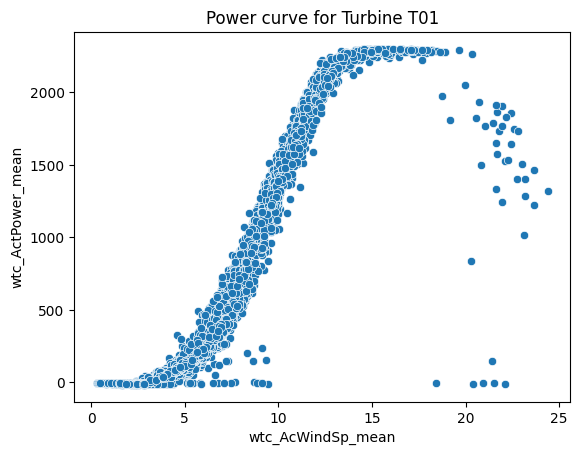

In [66]:
sns.scatterplot(data=t01_merged_df, x='wtc_AcWindSp_mean', y='wtc_ActPower_mean').set_title("Power curve for Turbine T01")
plt.show()

The power curve shows that the cut in wind speed is around 3-4m/s, where power starts to rise, and steep climp happens around 5-13m/s. There are some zero points between 5-10m/s and 18-22m/s that has good wind speed, which indicates stopped or faulty periods. There is some data on the top right that indicates a possible cut to the turbine's setpoint, which happens during high wind.

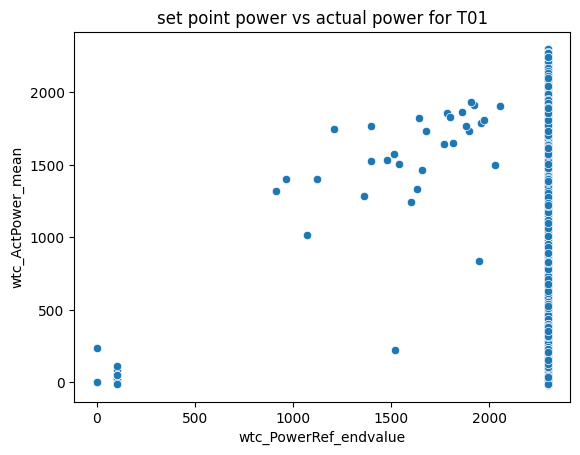

In [67]:
sns.scatterplot(data=t01_merged_df, x='wtc_PowerRef_endvalue', y='wtc_ActPower_mean').set_title("set point power vs actual power for T01")
plt.show()

In [58]:
t01_merged_df["wtc_PowerRef_endvalue"].value_counts().head(10)

,count
wtc_PowerRef_endvalue,
2300.0,4416
100.0,15
0.0,3
1518.0,1
1864.0,1
1787.0,1
1897.0,1
1772.0,1
2055.0,1


Almost every point sits around the setpoint of 2300 KW

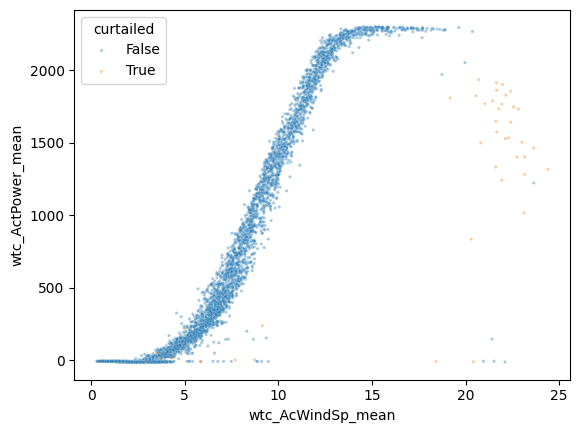

In [64]:
sns.scatterplot(data=t01_merged_df, x="wtc_AcWindSp_mean", y="wtc_ActPower_mean",
                hue="curtailed", s=5, alpha=0.4)
plt.show()

The orange points at top right signal protective derating during high winds. The low power points during moderate wind signal a stop or fault, the wtc_ScInOper_timeon, wtc_ScTurSto_timeon columns in the status table will be able to show more.



In [71]:
curtailed_t01 = t01_merged_df[t01_merged_df["curtailed"]]

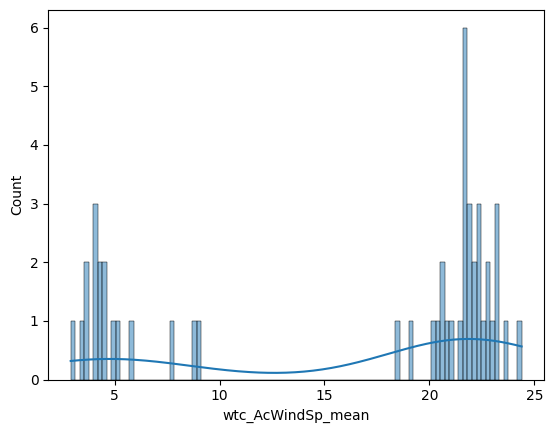

In [72]:
sns.histplot(data=curtailed_t01, x='wtc_AcWindSp_mean', bins=100, kde=True) # set kde=False to hide the curve
plt.show()

In [73]:
t01_merged_df[t01_merged_df["curtailed"]].groupby(t01_merged_df["wtc_PowerRef_endvalue"] < 500)["wtc_AcWindSp_mean"].describe()

,count,mean,std,min,25%,50%,75%,max
wtc_PowerRef_endvalue,,,,,,,,
False,31.0,21.446188,3.217273,5.066420,21.526410,21.935650,22.647181,24.393061
True,18.0,6.608946,4.992378,2.909062,4.089954,4.415211,7.234932,20.415180


## T02 analysis